
DATASET: Moons   |   n = 1000, features = 2
  SVM (RBF)               ->  test accuracy = 0.9400
  Logistic Regression     ->  test accuracy = 0.8833
  Random Forest           ->  test accuracy = 0.9400
  XGBoost                 ->  test accuracy = 0.9200
  MLP                     ->  test accuracy = 0.9233


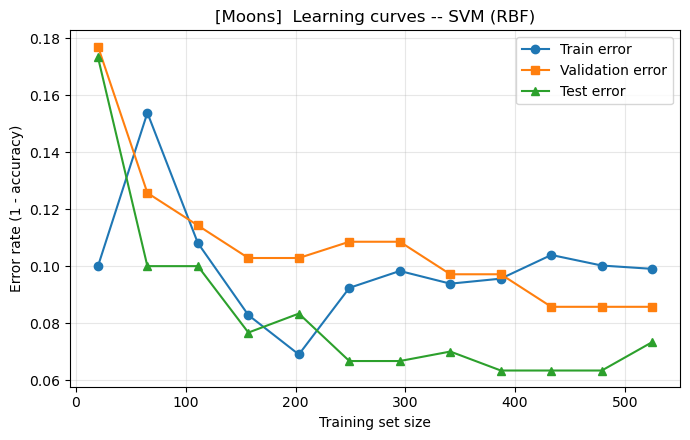

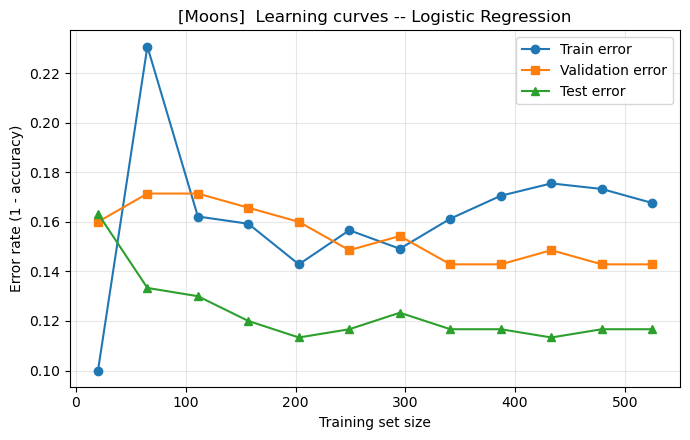

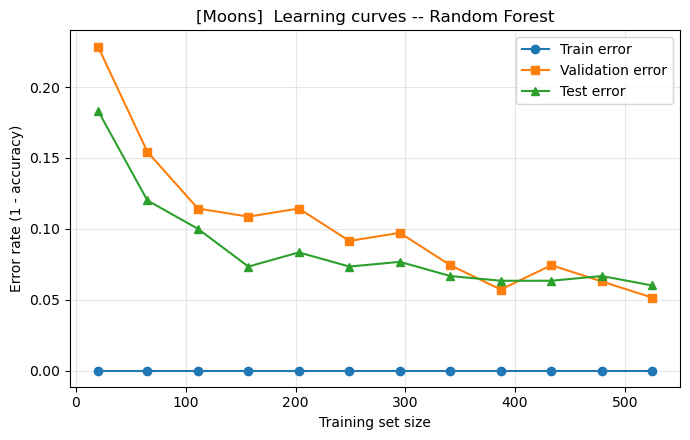

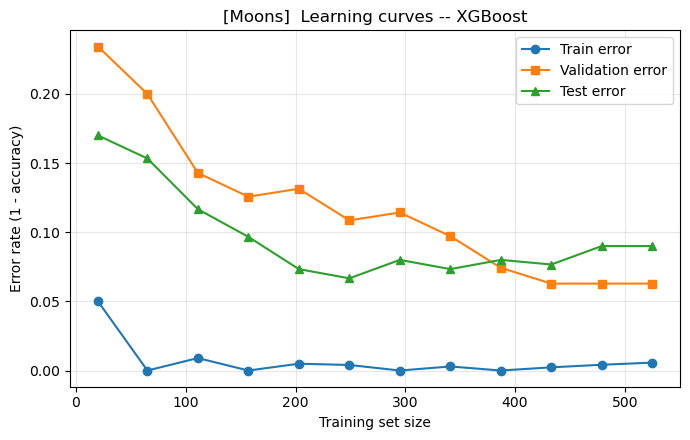

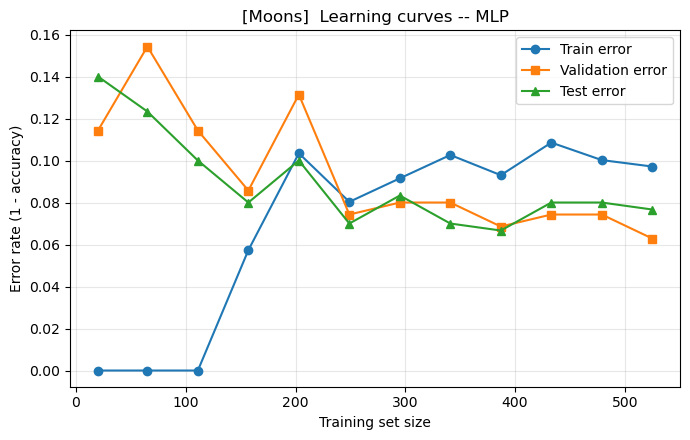

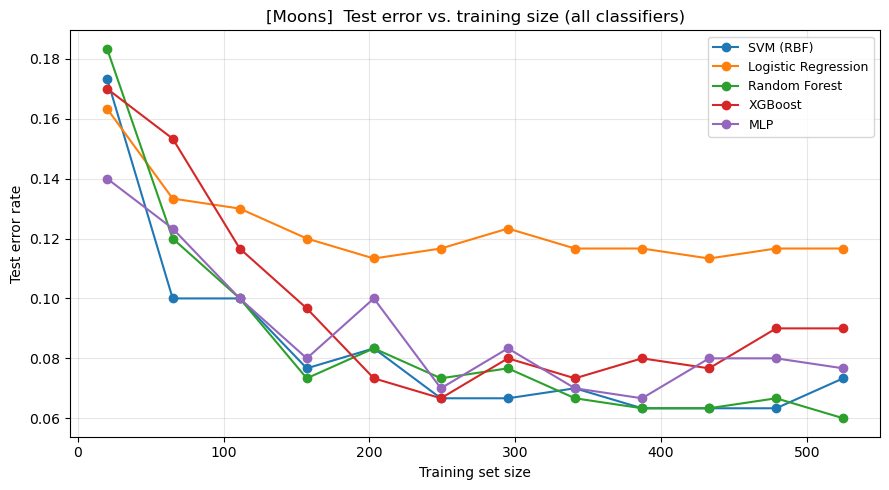

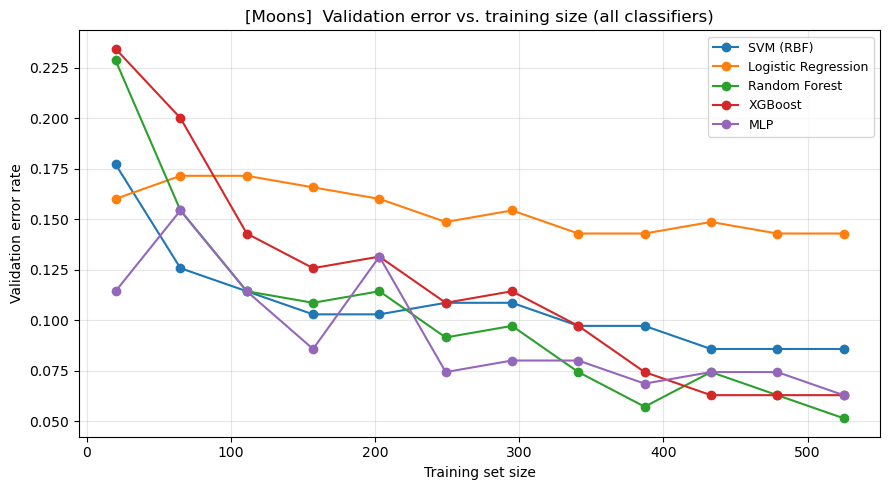


  Computing complexity curves...
    SVM (RBF)               best gamma = 12.3285     (val err = 0.057)
    Logistic Regression     best C = 0.0811131   (val err = 0.143)
    Random Forest           best max_depth = 10          (val err = 0.051)
    XGBoost                 best n_estimators = 55          (val err = 0.051)
    MLP                     best hidden_units = 32          (val err = 0.063)


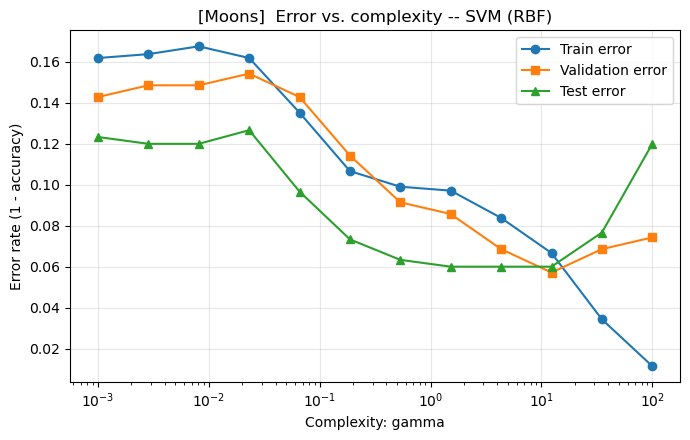

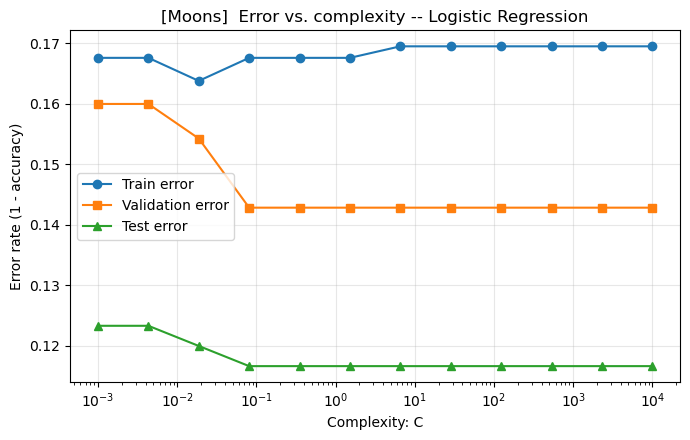

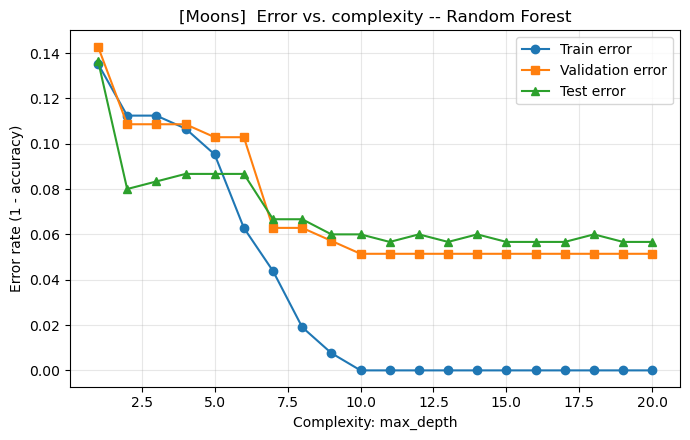

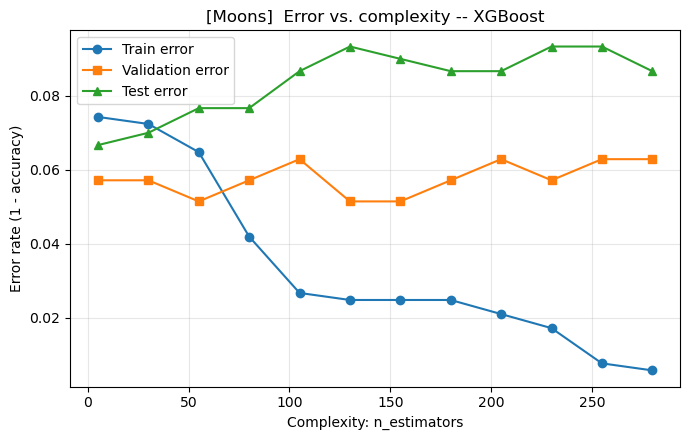

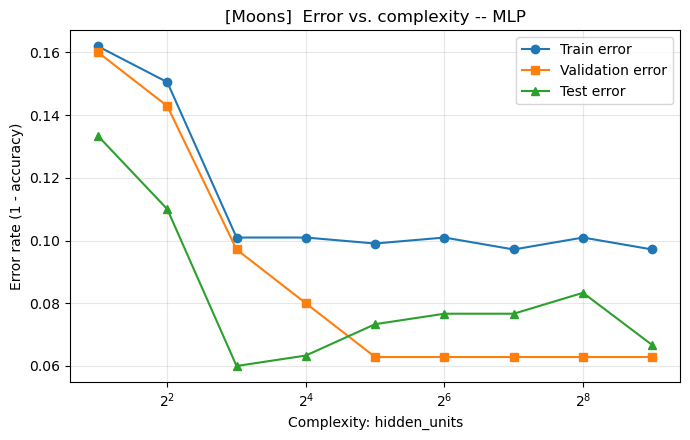

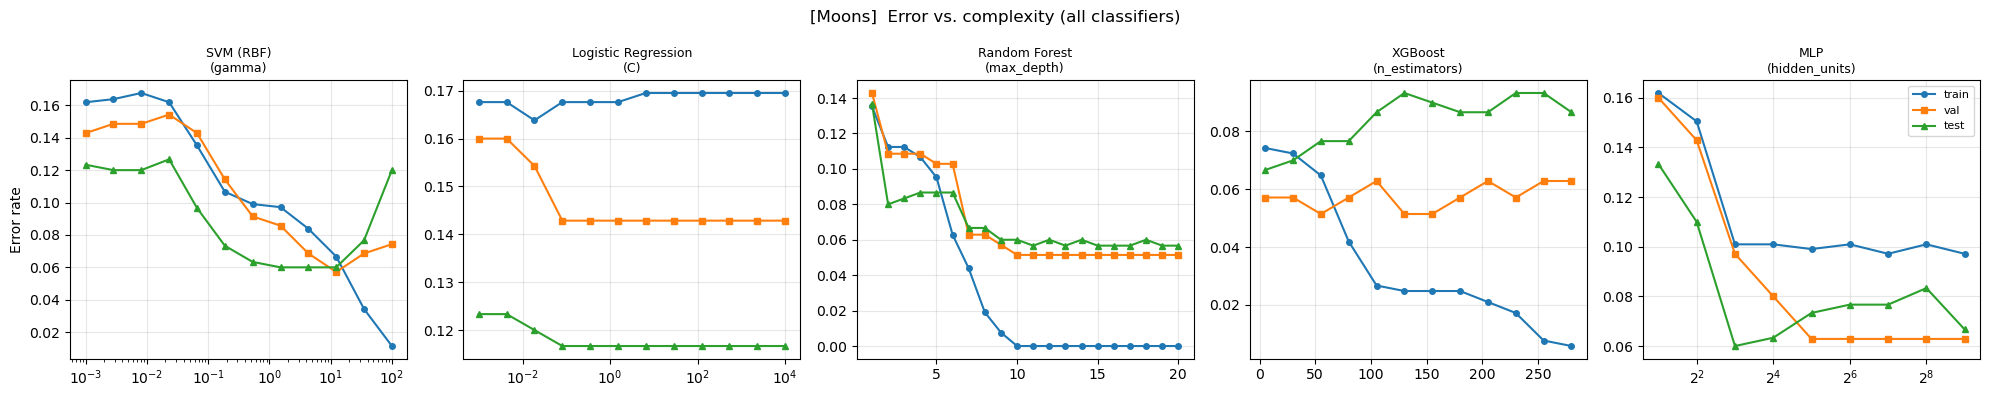

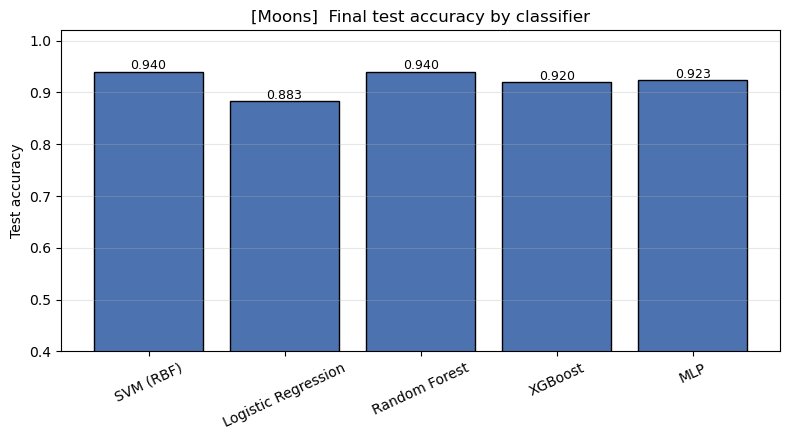

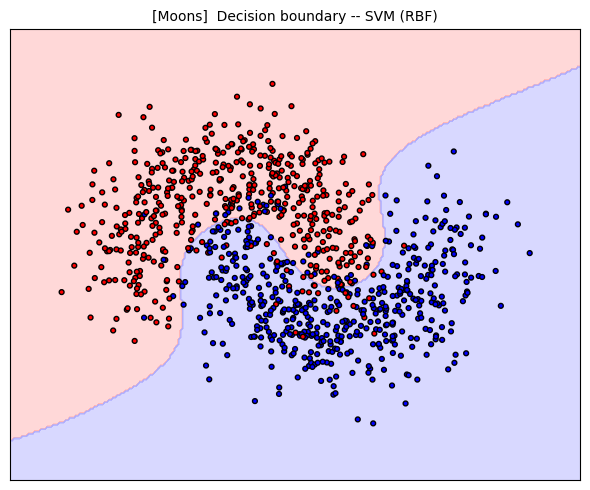

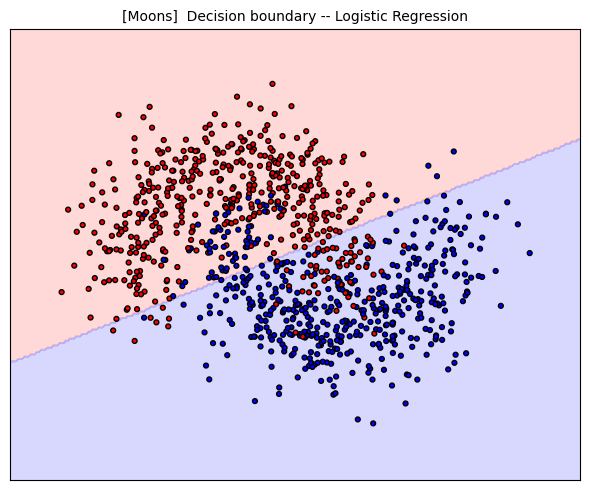

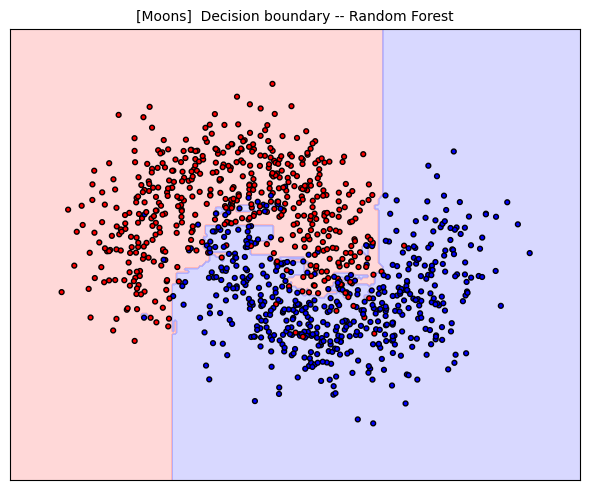

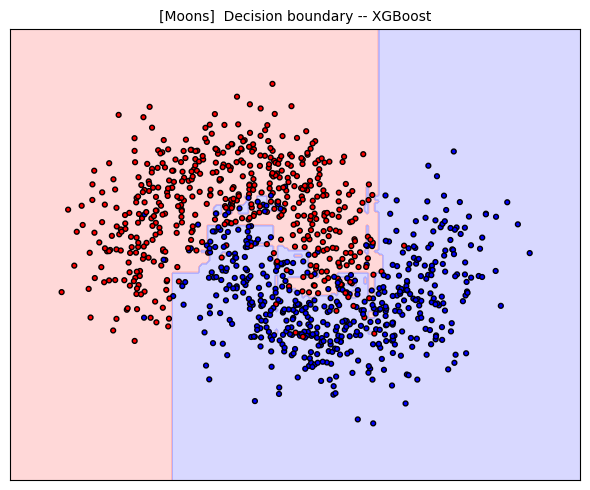

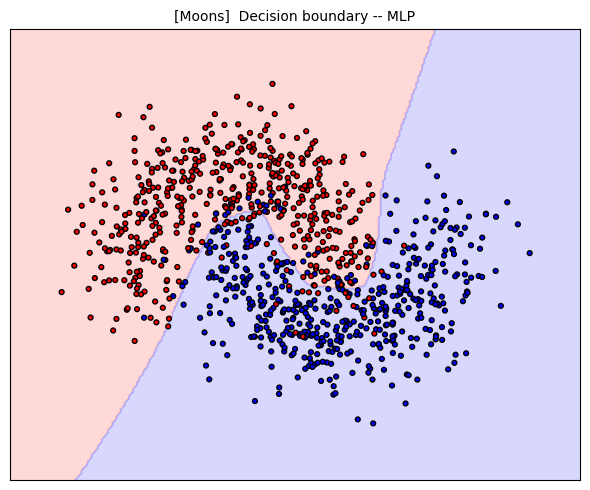

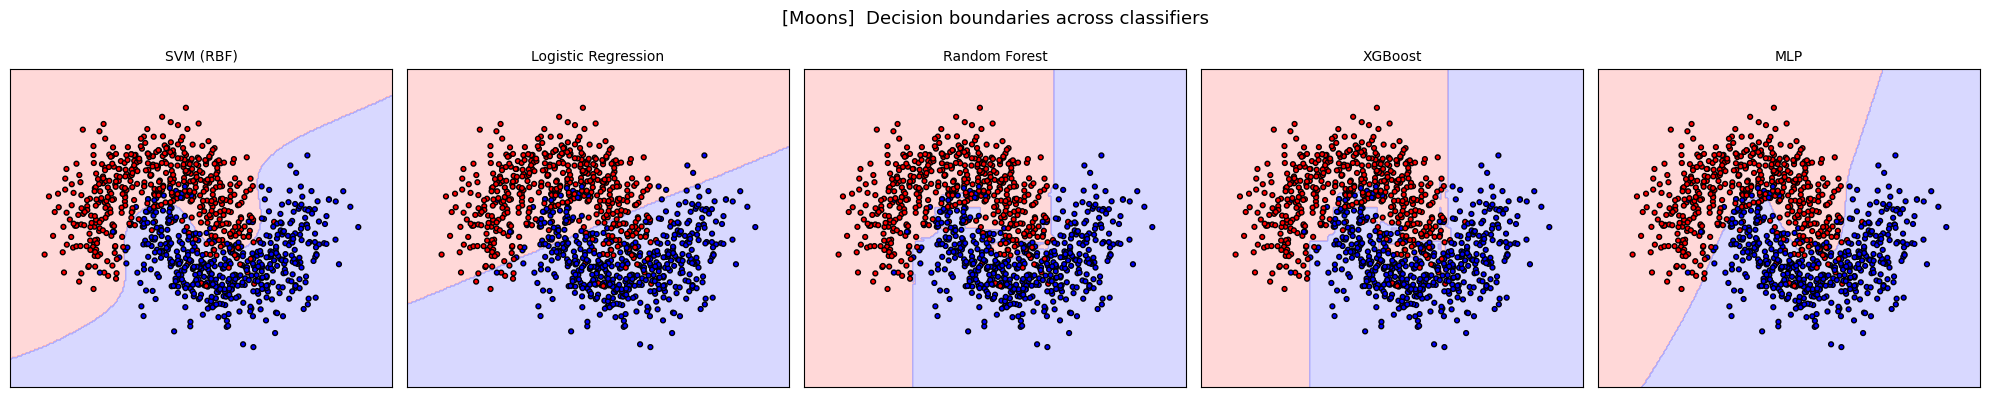


DATASET: Spirals   |   n = 1000, features = 2
  SVM (RBF)               ->  test accuracy = 0.9767
  Logistic Regression     ->  test accuracy = 0.5933
  Random Forest           ->  test accuracy = 0.9900
  XGBoost                 ->  test accuracy = 0.9900
  MLP                     ->  test accuracy = 0.9933


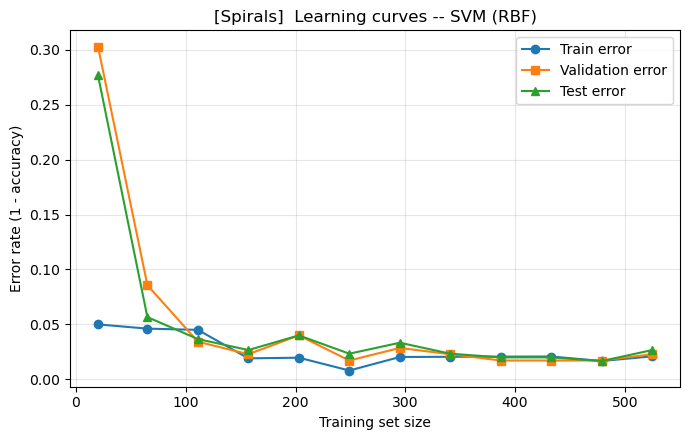

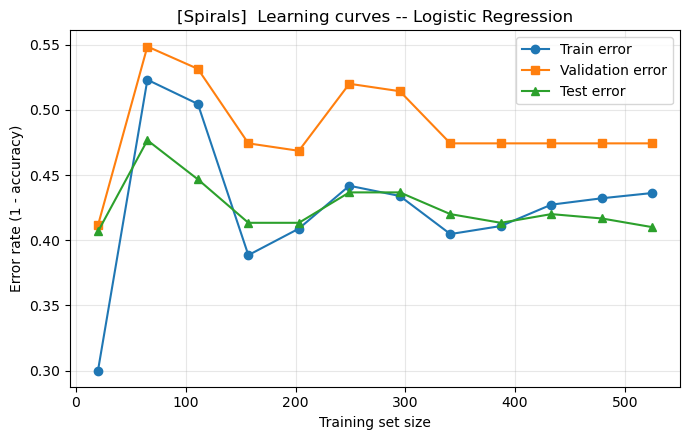

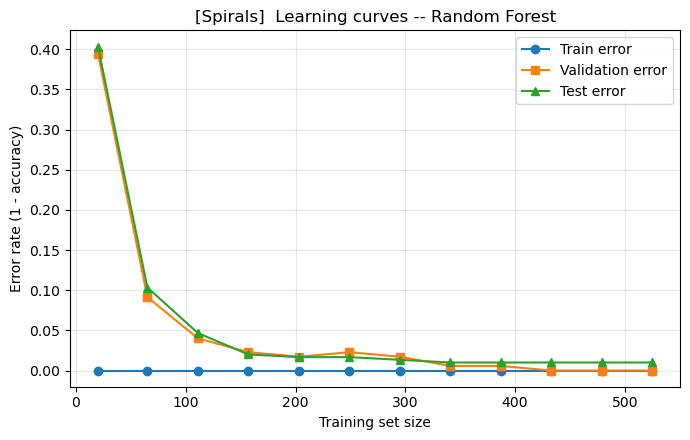

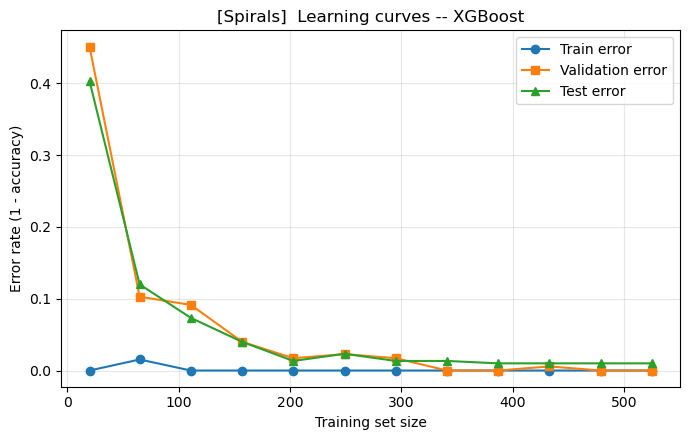

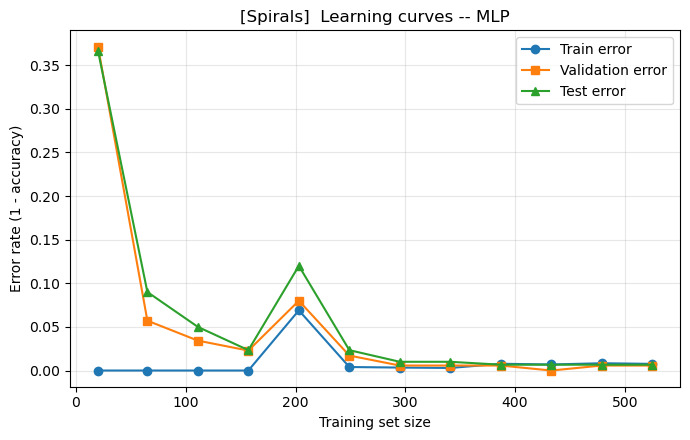

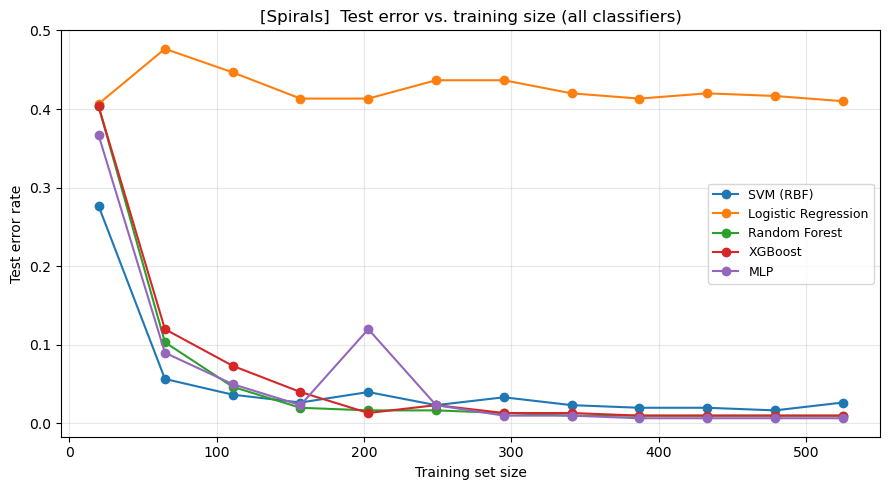

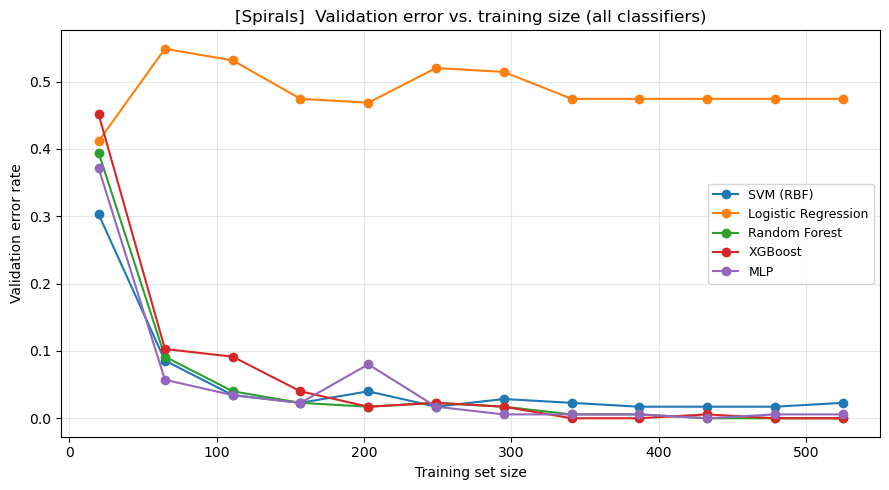


  Computing complexity curves...
    SVM (RBF)               best gamma = 35.1119     (val err = 0.006)
    Logistic Regression     best C = 0.0187382   (val err = 0.474)
    Random Forest           best max_depth = 10          (val err = 0.000)
    XGBoost                 best n_estimators = 30          (val err = 0.000)
    MLP                     best hidden_units = 16          (val err = 0.006)


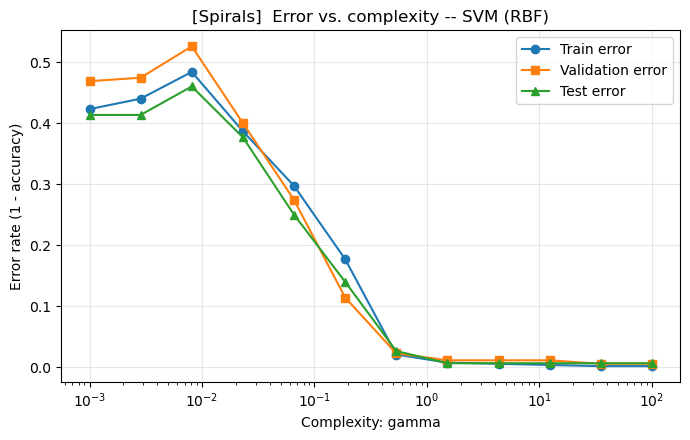

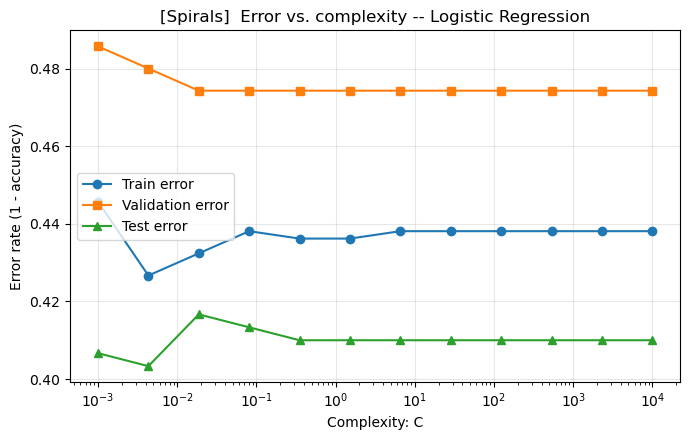

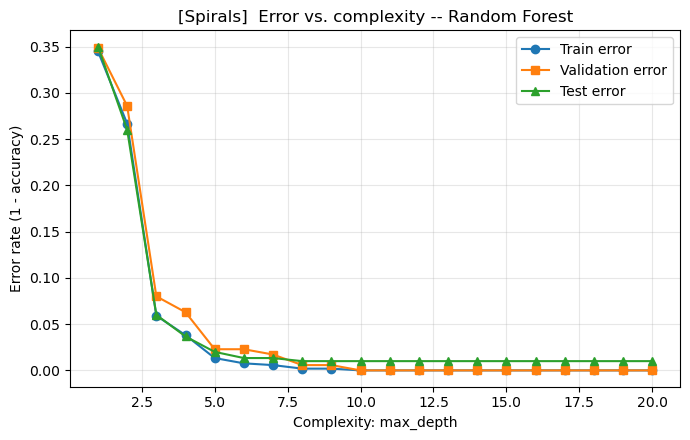

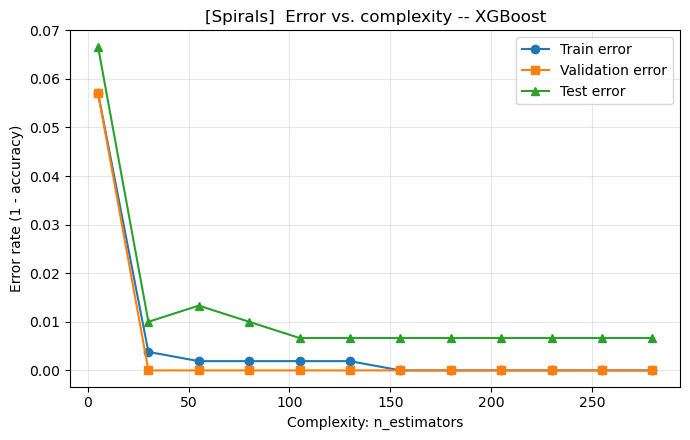

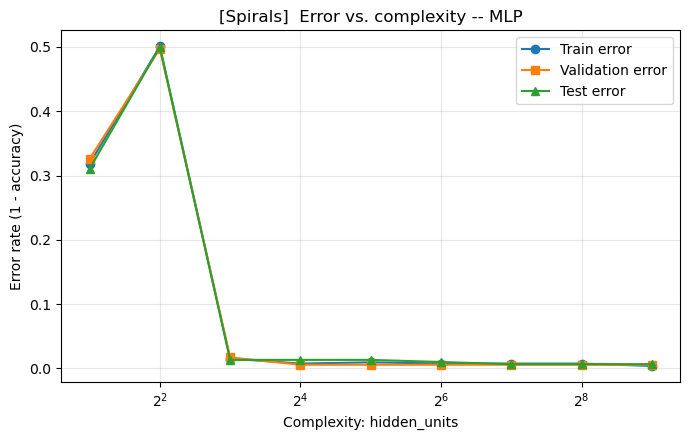

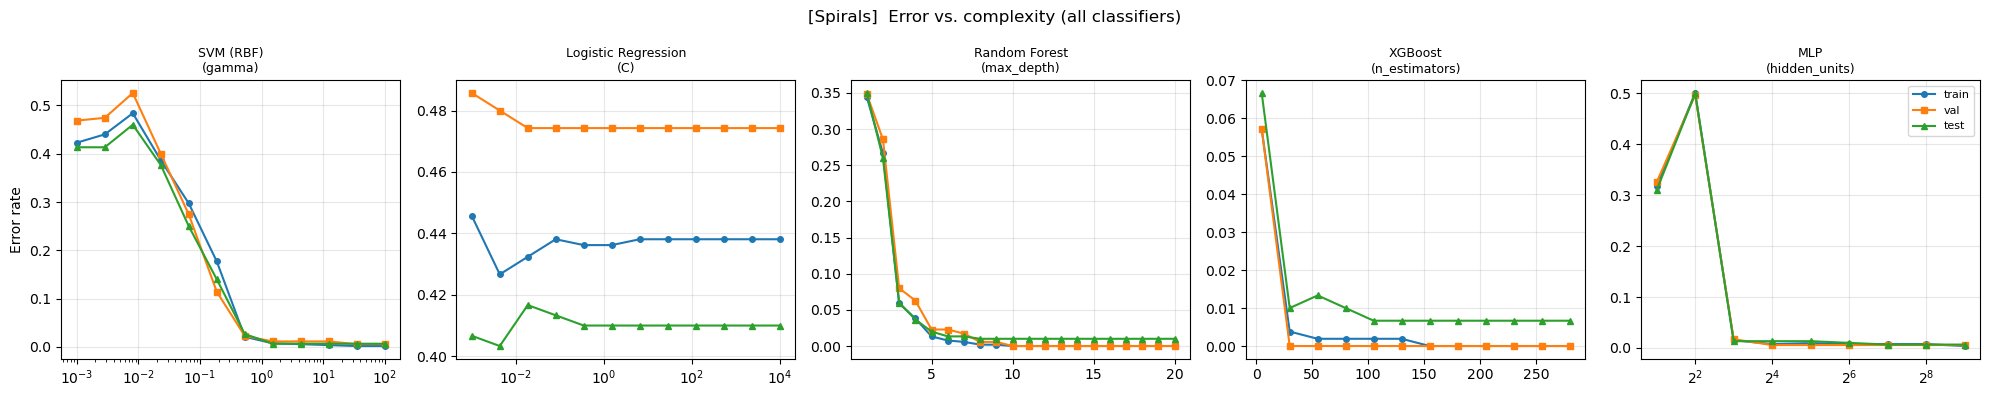

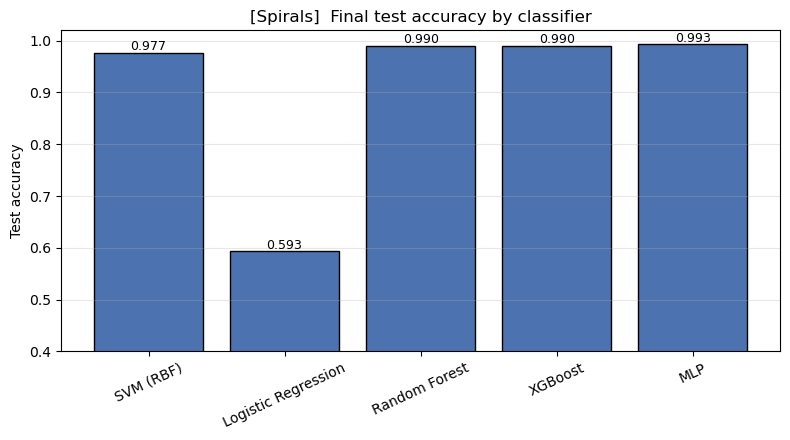

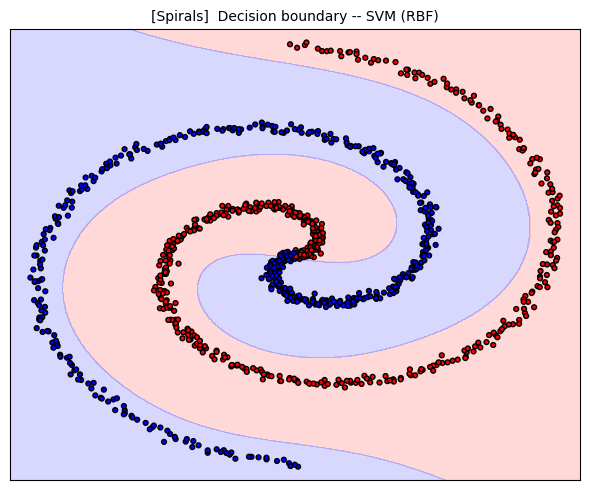

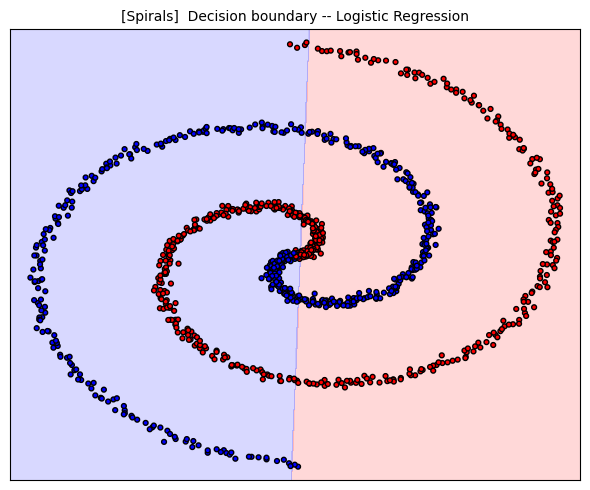

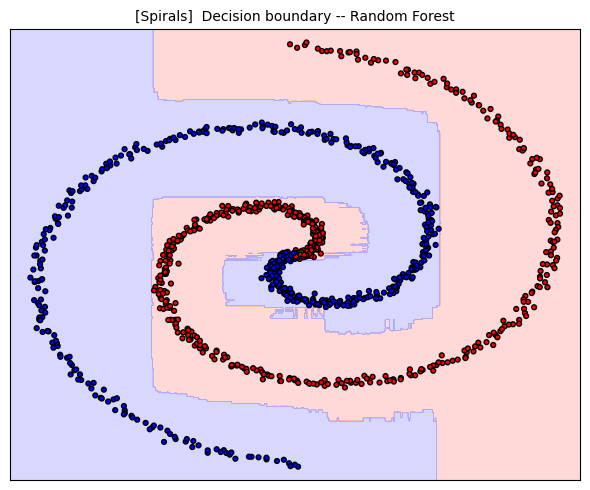

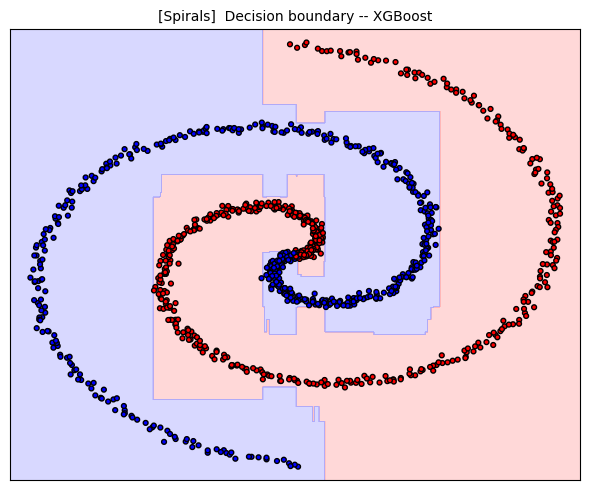

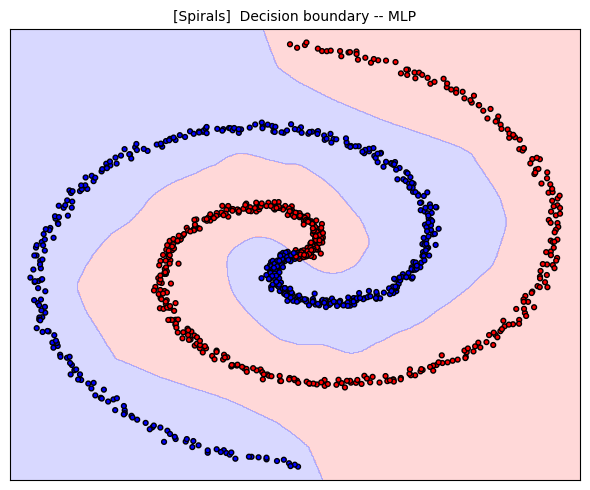

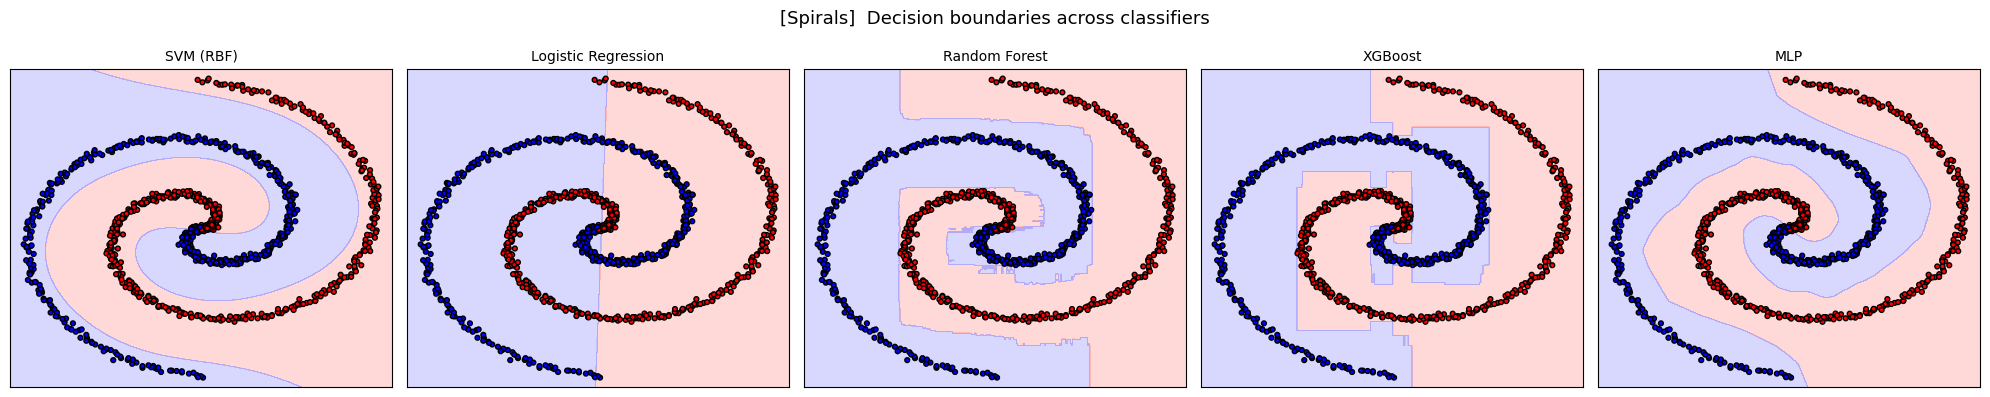

In [1]:
# =============================================================================
# Binary Classifier Comparison Toolkit -- Moons & Spirals
#   + Error vs. model complexity curves
# =============================================================================
# For each classifier we sweep the most characteristic "complexity" parameter:
#   - SVM (RBF)          : gamma         (kernel width; larger = more complex)
#   - Logistic Regression: C             (inverse regularization; larger = more complex)
#   - Random Forest      : max_depth     (deeper = more complex)
#   - XGBoost            : n_estimators  (more trees = more complex)
#   - MLP                : hidden size   (wider = more complex)
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

RNG = np.random.RandomState(42)

# =============================================================================
# 1. Dataset generators
# =============================================================================
def load_moons(n_samples=1000, noise=0.30):
    X, y = make_moons(n_samples=n_samples, noise=noise, random_state=42)
    return X, y


def load_spirals(n_samples=1000, noise=0.10, n_turns=2.5):
    n = n_samples // 2
    t = np.linspace(0.0, n_turns * np.pi, n)

    r1 = t
    x1 =  r1 * np.cos(t) + RNG.randn(n) * noise
    y1 =  r1 * np.sin(t) + RNG.randn(n) * noise

    r2 = t
    x2 = -r2 * np.cos(t) + RNG.randn(n) * noise
    y2 = -r2 * np.sin(t) + RNG.randn(n) * noise

    X = np.vstack([np.c_[x1, y1], np.c_[x2, y2]])
    y = np.hstack([np.zeros(n, dtype=int), np.ones(n, dtype=int)])
    idx = RNG.permutation(len(X))
    return X[idx], y[idx]


# =============================================================================
# 2. Classifier factory (default / "medium" settings)
# =============================================================================
def build_classifiers():
    return {
        'SVM (RBF)': make_pipeline(
            StandardScaler(),
            SVC(kernel='rbf', C=10.0, gamma='scale', probability=False, random_state=42)
        ),
        'Logistic Regression': make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, random_state=42)
        ),
        'Random Forest': RandomForestClassifier(
            n_estimators=300, max_depth=None, random_state=42, n_jobs=-1
        ),
        'XGBoost': XGBClassifier(
            n_estimators=300, max_depth=5, learning_rate=0.1,
            use_label_encoder=False, eval_metric='logloss',
            random_state=42, n_jobs=-1
        ),
        'MLP': make_pipeline(
            StandardScaler(),
            MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=2000,
                          random_state=42, early_stopping=False)
        ),
    }


# =============================================================================
# 3. Learning-curve computation (error vs. dataset size)
# =============================================================================
def compute_error_curves(clf, X_tr, y_tr, X_val, y_val, X_te, y_te,
                         n_points=12, min_size=20):
    n = len(X_tr)
    sizes = np.unique(np.linspace(min_size, n, n_points).astype(int))
    train_err, val_err, test_err = [], [], []
    for s in sizes:
        clf.fit(X_tr[:s], y_tr[:s])
        train_err.append(1 - accuracy_score(y_tr[:s], clf.predict(X_tr[:s])))
        val_err.append(1 - accuracy_score(y_val,   clf.predict(X_val)))
        test_err.append(1 - accuracy_score(y_te,   clf.predict(X_te)))
    return sizes, np.array(train_err), np.array(val_err), np.array(test_err)


# =============================================================================
# 4. Complexity-curve computation (error vs. hyperparameter)
# =============================================================================
def complexity_grid(name):
    """Return (label, values) for the complexity sweep of each classifier."""
    if name == 'SVM (RBF)':
        return 'gamma', np.logspace(-3, 2, 12)
    if name == 'Logistic Regression':
        return 'C', np.logspace(-3, 4, 12)
    if name == 'Random Forest':
        return 'max_depth', np.arange(1, 21)
    if name == 'XGBoost':
        return 'n_estimators', np.arange(5, 305, 25)
    if name == 'MLP':
        return 'hidden_units', np.array([2, 4, 8, 16, 32, 64, 128, 256, 512])
    raise ValueError(name)


def build_with_complexity(name, value):
    """Build a fresh classifier of the given type at the given complexity."""
    if name == 'SVM (RBF)':
        return make_pipeline(StandardScaler(),
                             SVC(kernel='rbf', C=10.0, gamma=value, random_state=42))
    if name == 'Logistic Regression':
        return make_pipeline(StandardScaler(),
                             LogisticRegression(C=value, max_iter=2000, random_state=42))
    if name == 'Random Forest':
        return RandomForestClassifier(n_estimators=300, max_depth=int(value),
                                      random_state=42, n_jobs=-1)
    if name == 'XGBoost':
        return XGBClassifier(n_estimators=int(value), max_depth=5,
                             learning_rate=0.1, use_label_encoder=False,
                             eval_metric='logloss', random_state=42, n_jobs=-1)
    if name == 'MLP':
        h = int(value)
        return make_pipeline(StandardScaler(),
                             MLPClassifier(hidden_layer_sizes=(h, max(h // 2, 2)),
                                           max_iter=2000, random_state=42,
                                           early_stopping=False))
    raise ValueError(name)


def compute_complexity_curves(name, X_tr, y_tr, X_val, y_val, X_te, y_te):
    """Sweep the complexity hyperparameter of the given classifier type."""
    param_name, values = complexity_grid(name)
    tr_err, va_err, te_err = [], [], []
    for v in values:
        clf = build_with_complexity(name, v)
        clf.fit(X_tr, y_tr)
        tr_err.append(1 - accuracy_score(y_tr, clf.predict(X_tr)))
        va_err.append(1 - accuracy_score(y_val, clf.predict(X_val)))
        te_err.append(1 - accuracy_score(y_te, clf.predict(X_te)))
    return param_name, values, np.array(tr_err), np.array(va_err), np.array(te_err)


# =============================================================================
# 5. Decision-boundary plotting
# =============================================================================
def plot_decision_boundary(clf, X, y, title, ax, h=0.02):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    cmap_bg = ListedColormap(['#FFAAAA', '#AAAAFF'])
    cmap_pt = ListedColormap(['#FF0000', '#0000FF'])
    ax.contourf(xx, yy, Z, cmap=cmap_bg, alpha=0.45)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_pt, edgecolor='k', s=12)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xticks(()); ax.set_yticks(())


# =============================================================================
# 6. Full pipeline for one dataset
# =============================================================================
def run_pipeline(dataset_name, X, y):
    print("\n" + "=" * 72)
    print(f"DATASET: {dataset_name}   |   n = {len(X)}, features = {X.shape[1]}")
    print("=" * 72)

    # --- 3-way split ---
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.25,
        random_state=42, stratify=y_train_full
    )

    # -------------------------------------------------------------------------
    # A. Default-config performance + learning curves (error vs. dataset size)
    # -------------------------------------------------------------------------
    classifiers = build_classifiers()
    results = {}

    for name, clf in classifiers.items():
        sizes, tr, va, te = compute_error_curves(
            clf, X_train, y_train, X_val, y_val, X_test, y_test
        )
        results[name] = dict(sizes=sizes, train=tr, val=va, test=te)

        clf.fit(X_train_full, y_train_full)
        acc = accuracy_score(y_test, clf.predict(X_test))
        print(f"  {name:22s}  ->  test accuracy = {acc:.4f}")

    # Per-classifier learning curves
    for name, r in results.items():
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.plot(r['sizes'], r['train'], 'o-', label='Train error',      color='#1f77b4')
        ax.plot(r['sizes'], r['val'],   's-', label='Validation error', color='#ff7f0e')
        ax.plot(r['sizes'], r['test'],  '^-', label='Test error',       color='#2ca02c')
        ax.set_xlabel('Training set size')
        ax.set_ylabel('Error rate (1 - accuracy)')
        ax.set_title(f'[{dataset_name}]  Learning curves -- {name}')
        ax.legend(); ax.grid(alpha=0.3)
        plt.tight_layout(); plt.show()

    # Comparison: test-error curves
    fig, ax = plt.subplots(figsize=(9, 5))
    for name, r in results.items():
        ax.plot(r['sizes'], r['test'], 'o-', label=name)
    ax.set_xlabel('Training set size')
    ax.set_ylabel('Test error rate')
    ax.set_title(f'[{dataset_name}]  Test error vs. training size (all classifiers)')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    # Comparison: validation-error curves
    fig, ax = plt.subplots(figsize=(9, 5))
    for name, r in results.items():
        ax.plot(r['sizes'], r['val'], 'o-', label=name)
    ax.set_xlabel('Training set size')
    ax.set_ylabel('Validation error rate')
    ax.set_title(f'[{dataset_name}]  Validation error vs. training size (all classifiers)')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    # -------------------------------------------------------------------------
    # B. Complexity curves (error vs. hyperparameter)
    # -------------------------------------------------------------------------
    print("\n  Computing complexity curves...")
    complexity_results = {}
    for name in classifiers:
        pname, pvals, tr, va, te = compute_complexity_curves(
            name, X_train, y_train, X_val, y_val, X_test, y_test
        )
        complexity_results[name] = dict(
            param=pname, values=pvals, train=tr, val=va, test=te
        )
        # Report the value that minimizes validation error
        best_i = int(np.argmin(va))
        print(f"    {name:22s}  best {pname} = {pvals[best_i]:<10g}  "
              f"(val err = {va[best_i]:.3f})")

    # Per-classifier complexity curves
    for name, r in complexity_results.items():
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.plot(r['values'], r['train'], 'o-', label='Train error',      color='#1f77b4')
        ax.plot(r['values'], r['val'],   's-', label='Validation error', color='#ff7f0e')
        ax.plot(r['values'], r['test'],  '^-', label='Test error',       color='#2ca02c')
        ax.set_xlabel(f'Complexity: {r["param"]}')
        ax.set_ylabel('Error rate (1 - accuracy)')
        ax.set_title(f'[{dataset_name}]  Error vs. complexity -- {name}')
        # Log x-axis for parameters that span orders of magnitude
        if r['param'] in ('gamma', 'C'):
            ax.set_xscale('log')
        if r['param'] == 'hidden_units':
            ax.set_xscale('log', base=2)
        ax.legend(); ax.grid(alpha=0.3)
        plt.tight_layout(); plt.show()

    # Combined panel of complexity curves (small multiples)
    n = len(complexity_results)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    for ax, (name, r) in zip(axes, complexity_results.items()):
        ax.plot(r['values'], r['train'], 'o-', label='train',  color='#1f77b4', ms=4)
        ax.plot(r['values'], r['val'],   's-', label='val',    color='#ff7f0e', ms=4)
        ax.plot(r['values'], r['test'],  '^-', label='test',   color='#2ca02c', ms=4)
        if r['param'] in ('gamma', 'C'):
            ax.set_xscale('log')
        if r['param'] == 'hidden_units':
            ax.set_xscale('log', base=2)
        ax.set_title(f'{name}\n({r["param"]})', fontsize=9)
        ax.grid(alpha=0.3)
    axes[0].set_ylabel('Error rate')
    axes[-1].legend(fontsize=8)
    fig.suptitle(f'[{dataset_name}]  Error vs. complexity (all classifiers)', fontsize=12)
    plt.tight_layout(); plt.show()

    # -------------------------------------------------------------------------
    # C. Final-accuracy bar chart + decision boundaries
    # -------------------------------------------------------------------------
    final_acc = {}
    for name, clf in classifiers.items():
        clf.fit(X_train_full, y_train_full)
        final_acc[name] = accuracy_score(y_test, clf.predict(X_test))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    names  = list(final_acc.keys())
    values = [final_acc[n] for n in names]
    bars = ax.bar(names, values, color='#4c72b0', edgecolor='black')
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.005,
                f'{v:.3f}', ha='center', fontsize=9)
    ax.set_ylim(0.4, 1.02)
    ax.set_ylabel('Test accuracy')
    ax.set_title(f'[{dataset_name}]  Final test accuracy by classifier')
    ax.tick_params(axis='x', rotation=25); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()

    for name, clf in classifiers.items():
        clf.fit(X_train_full, y_train_full)
        fig, ax = plt.subplots(figsize=(6, 5))
        plot_decision_boundary(clf, X, y,
                               f'[{dataset_name}]  Decision boundary -- {name}', ax)
        plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, len(classifiers),
                             figsize=(4 * len(classifiers), 4))
    for ax, (name, clf) in zip(axes, classifiers.items()):
        clf.fit(X_train_full, y_train_full)
        plot_decision_boundary(clf, X, y, name, ax)
    fig.suptitle(f'[{dataset_name}]  Decision boundaries across classifiers',
                 fontsize=13)
    plt.tight_layout(); plt.show()


# =============================================================================
# 7. Run both datasets
# =============================================================================
X_moons, y_moons     = load_moons(n_samples=1000, noise=0.30)
X_spirals, y_spirals = load_spirals(n_samples=1000, noise=0.10, n_turns=2.5)

run_pipeline("Moons",   X_moons,   y_moons)
run_pipeline("Spirals", X_spirals, y_spirals)